In [44]:
import os
import csv
from PIL import Image

import numpy as np
import torch
import random
import cv2
from torch.utils.data import Dataset, DataLoader
from collections import defaultdict


class CKPlusDataset(Dataset):
    def __init__(self, csv_path, images_dir, fold_to_use, is_train=True,
                 num_folds=10, random_seed=42, img_width=48, img_height=48, transform=None):
        """
        PyTorch equivalent of dataset::CK_Plus
        """
        self.images_dir = images_dir
        self.img_width = img_width
        self.img_height = img_height
        self.transform = transform

        # 1. Read CSV
        all_sequences = []
        with open(csv_path, 'r') as f:
            reader = csv.reader(f)
            for row in reader:
                if len(row) < 3: continue
                subject, ipostase, emotion = row[0].strip(), int(row[1].strip()), int(row[2].strip())
                all_sequences.append({
                    'subject': subject,
                    'ipostase': ipostase,
                    'emotion': emotion
                })

        # 2. Replicate C++ Distribution Logic
        sequences_by_emotion = defaultdict(list)
        for seq in all_sequences:
            sequences_by_emotion[seq['emotion']].append(seq)

        rng = random.Random(random_seed)
        folds_data = {f: [] for f in range(1, num_folds + 1)}

        for emotion, emotion_sequences in sequences_by_emotion.items():
            rng.shuffle(emotion_sequences)
            for i, seq in enumerate(emotion_sequences):
                fold = (i % num_folds) + 1
                folds_data[fold].append(seq)

        # 3. Filter for Train/Test
        self.data = []
        if is_train:
            for f in range(1, num_folds + 1):
                if f != fold_to_use:
                    self.data.extend(folds_data[f])
        else:
            self.data.extend(folds_data[fold_to_use])

        valid_data = []
        for seq in self.data:
            subject = seq['subject']
            ipostase_str = f"{seq['ipostase']:03d}"
            seq_dir = os.path.join(self.images_dir, subject, ipostase_str)
            if os.path.exists(seq_dir):
                valid_data.append(seq)
        self.data = valid_data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        seq = self.data[idx]
        subject = seq['subject']
        ipostase_str = f"{seq['ipostase']:03d}"
        label = seq['emotion'] - 1
        seq_dir = os.path.join(self.images_dir, subject, ipostase_str)
    
        valid_extensions = ('.png', '.jpg', '.jpeg')
        img_names = [f for f in os.listdir(seq_dir) if f.lower().endswith(valid_extensions)]
        img_names.sort()
    
        frames = []
        for img_name in img_names:
            img_path = os.path.join(seq_dir, img_name)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is None: continue
    
            # 1. Convert NumPy array (OpenCV) to PIL Image
            img = Image.fromarray(img)
    
            # 2. Apply transforms
            if self.transform:
                # This will Resize, Grayscale(3), Flip, ToTensor, and Normalize
                img = self.transform(img)
            else:
                # Fallback if no transform is provided: 
                # Manual resize and conversion to tensor
                img = cv2.resize(np.array(img), (self.img_width, self.img_height))
                img = torch.from_numpy(img).float() / 255.0
                img = img.unsqueeze(0) # Add channel dim (1, H, W)
    
            frames.append(img)
    
        # 3. Stack frames into (Channels, Depth, Height, Width)
        # Since ToTensor() in transforms already returns (C, H, W), 
        # stacking them on dim 1 creates (C, T, H, W)
        tensor_3d = torch.stack(frames, dim=0) 
    
        return tensor_3d, torch.tensor(label, dtype=torch.long)

MAX_FRAMES = 10 # Adjust this to the actual maximum frame count in your CK+ dataset

def pad_collate_fn(batch):
    """
    Since CK+ sequences have different lengths (e.g., some are 12 frames, some 25),
    we must pad the temporal/depth dimension so we can stack them into batches.
    """
    # batch is a list of tuples: [(tensor1, label1), (tensor2, label2), ...]
    tensors, labels = zip(*batch)

    padded_tensors = []
    for t in tensors:
        c, d, h, w = t.shape
        pad_size = MAX_FRAMES - d

        # PyTorch pad syntax starts from the last dimension and moves backwards.
        # Format: (PadLeft, PadRight, PadTop, PadBottom, PadFront, PadBack)
        # We only want to pad the 'Back' of the temporal dimension.
        if pad_size > 0:
            padded = torch.nn.functional.pad(t, (0, 0, 0, 0, 0, pad_size), "constant", 0)
        else:
            padded = t  # If you have sequences longer than MAX_FRAMES, you would slice them here: t[:, :MAX_FRAMES, :, :]
        padded_tensors.append(padded)

    return torch.stack(padded_tensors), torch.stack(labels)

In [47]:


from torchvision import transforms

EFFICIENTNET_MEAN = [0.485, 0.456, 0.406]
EFFICIENTNET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),  # CK+ is grayscale → repeat to 3ch
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(EFFICIENTNET_MEAN, EFFICIENTNET_STD),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(EFFICIENTNET_MEAN, EFFICIENTNET_STD),
])

# Pass these to your CKPlusDataset via a `transform=` argument


# ── 3. Training loop with two-phase transfer learning ────────────────────────

PHASE1_EPOCHS = 5       # head-only warm-up (fast, prevents destroying pre-trained weights)
PHASE2_EPOCHS = 30      # full fine-tune
BATCH_SIZE    = 32
DEVICE        = "cuda"
NUM_FOLDS     = 2



def run_epoch(model, loader, criterion, optimizer, device, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)

            if train:
                optimizer.zero_grad()

            logits, _ = model(inputs)
            loss = criterion(logits, labels)

            if train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * inputs.size(0)
            correct    += (logits.argmax(1) == labels).sum().item()
            total      += labels.size(0)

    return total_loss / total, 100 * correct / total

In [51]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader

# ── 1. Arhitectura Modelului ──────────────────────────────────────────────────

class EmotionCNN_LSTM(nn.Module):
    def __init__(self, num_classes=7, hidden_dim=256, num_layers=1, dropout=0.5):
        super().__init__()
        
        # 1. Extractorul 2D (ResNet18)
        resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
        # Păstrăm totul în afară de layer-ul final (fc). 
        # AdaptiveAvgPool2d rămâne, deci output-ul este (B, 512, 1, 1)
        self.cnn = nn.Sequential(*list(resnet.children())[:-1]) 
        self.cnn_out_dim = 512
        
        # 2. Modulul Temporal (LSTM)
        self.lstm = nn.LSTM(
            input_size=self.cnn_out_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        # 3. Capul de Clasificare
        self.fc = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout * 0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # R3D se aștepta la (B, C, T, H, W). 
        # Ne asigurăm că formatul este (B, T, C, H, W) pentru LSTM.
        if x.dim() == 5 and x.shape[1] == 3:
            x = x.permute(0, 2, 1, 3, 4) 
            
        B, T, C, H, W = x.shape
        
        # Facem flatten la Batch și Time pentru a procesa toate imaginile simultan prin CNN
        c_in = x.contiguous().view(B * T, C, H, W)
        
        # Extragem trăsăturile
        cnn_out = self.cnn(c_in)          # Output: (B*T, 512, 1, 1)
        cnn_out = cnn_out.view(B, T, -1)  # Re-separăm cadrele: (B, T, 512)
        
        # Trecem prin LSTM
        lstm_out, (h_n, c_n) = self.lstm(cnn_out) 
        
        # Luăm starea ascunsă de la ultimul cadru (apex-ul expresiei)
        last_hidden_state = h_n[-1, :, :] # Output: (B, hidden_dim)
        
        logits = self.fc(last_hidden_state)
        return logits, None  # (logits, _) pentru a păstra compatibilitatea cu run_epoch


# ── 2. Funcția de control al greutăților ──────────────────────────────────────

def set_trainable_layers_lstm(model, phase):
    """
    Phase 1: Doar LSTM și FC (antrenăm capul temporal să înțeleagă trăsăturile ResNet)
    Phase 2: Layer4 (din CNN) + LSTM + FC (fine-tuning delicat)
    """
    # 1. Înghețăm absolut tot
    for param in model.parameters():
        param.requires_grad = False
        
    # 2. Dezghețăm selectiv
    if phase == 1:
        for param in model.lstm.parameters(): param.requires_grad = True
        for param in model.fc.parameters():   param.requires_grad = True
            
    elif phase == 2:
        # Layer 4 în ResNet18 standard este la indexul 7 în `children()`
        for param in model.cnn[7].parameters(): param.requires_grad = True
        for param in model.lstm.parameters():   param.requires_grad = True
        for param in model.fc.parameters():     param.requires_grad = True

    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  Trainable params (Phase {phase}): {n_trainable:,}")


# ── 3. Bucla de Antrenare ─────────────────────────────────────────────────────

PHASE1_EPOCHS = 10   # Lăsăm puțin mai mult timp LSTM-ului să se stabilizeze
PHASE2_EPOCHS = 30   # Epoci de fine-tuning
BATCH_SIZE    = 16   # Poți crește la 32 dacă îți permite memoria GPU-ului
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CSV_PATH = "bigdata/md5_s9055eb881c182cc82d1ab85ba6c/licenta/csnn_simulator/dataset/CK+/emotions_dataset.csv"
IMAGES_DIR = "CK_Plus_Cropped"

NUM_FOLDS = 10

all_fold_accuracies = []

for fold in range(1, NUM_FOLDS + 1):
    print(f"\n{'='*55}\nFOLD {fold}\n{'='*55}")

    train_dataset = CKPlusDataset(
        csv_path=CSV_PATH, images_dir=IMAGES_DIR,
        fold_to_use=fold, is_train=True, random_seed=42,
        transform=train_transform,
    )
    test_dataset = CKPlusDataset(
        csv_path=CSV_PATH, images_dir=IMAGES_DIR,
        fold_to_use=fold, is_train=False, random_seed=42,
        transform=test_transform,
    )

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

    # Inițializăm noul model
    model     = EmotionCNN_LSTM(num_classes=7).to(DEVICE)
    # Folosim un pic mai mult label smoothing pentru a combate overfitting-ul
    criterion = nn.CrossEntropyLoss(label_smoothing=0.15) 

    # ── Phase 1: LSTM + Head Only ─────────────────────────────────────────────
    print(f"\n[Phase 1] Warm-up LSTM & Head ({PHASE1_EPOCHS} epochs)")
    set_trainable_layers_lstm(model, phase=1)

    opt1 = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=1e-3, weight_decay=1e-4
    )

    for epoch in range(1, PHASE1_EPOCHS + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, opt1, DEVICE, train=True)
        te_loss, te_acc = run_epoch(model, test_loader,  criterion, None, DEVICE, train=False)
        print(f"  {epoch:2d}/{PHASE1_EPOCHS} | Train {tr_acc:.1f}% | Test {te_acc:.1f}%")

    # ── Phase 2: CNN(Layer4) + LSTM + Head ────────────────────────────────────
    print(f"\n[Phase 2] Fine-tune Layer4 + LSTM ({PHASE2_EPOCHS} epochs)")
    set_trainable_layers_lstm(model, phase=2)

    # LR mult mai mic (1e-4 în loc de 3e-4) pentru a nu distruge ponderile ResNet-ului
    opt2 = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=1e-4, weight_decay=1e-2  # weight_decay crescut pentru regularizare
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=PHASE2_EPOCHS, eta_min=1e-6)

    best_acc, patience_count = 0.0, 0
    PATIENCE = 10  # Oprim dacă nu avem îmbunătățiri timp de 10 epoci

    for epoch in range(1, PHASE2_EPOCHS + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, opt2, DEVICE, train=True)
        te_loss, te_acc = run_epoch(model, test_loader,  criterion, None, DEVICE, train=False)
        scheduler.step()

        gap  = tr_acc - te_acc
        flag = ""
        if te_acc > best_acc:
            best_acc = te_acc
            patience_count = 0
            torch.save(model.state_dict(), f"best_cnn_lstm_fold{fold}v2.pth")
            flag = " ★"
        else:
            patience_count += 1

        print(f"  {epoch:2d}/{PHASE2_EPOCHS} | "
              f"Train {tr_acc:.1f}% | Test {te_acc:.1f}% | "
              f"Gap {gap:+.1f}%{flag}")

        if patience_count >= PATIENCE:
            print(f"  Early stop — no improvement for {PATIENCE} epochs.")
            break

    all_fold_accuracies.append(best_acc)

    print(f"\nFold {fold} best: {best_acc:.2f}%")

# DUPĂ ce se termină bucla de 10 fold-uri:
import numpy as np

mean_acc = np.mean(all_fold_accuracies)
std_acc = np.std(all_fold_accuracies)

print(f"\nFinal Cross-Validation Results:")
print(f"Mean Accuracy: {mean_acc:.2f}%")
print(f"Standard Deviation: {std_acc:.2f}%")


FOLD 1

[Phase 1] Warm-up LSTM & Head (10 epochs)
  Trainable params (Phase 1): 822,279
   1/10 | Train 19.9% | Test 27.3%
   2/10 | Train 35.5% | Test 30.3%
   3/10 | Train 47.8% | Test 54.5%
   4/10 | Train 52.5% | Test 69.7%
   5/10 | Train 56.5% | Test 69.7%
   6/10 | Train 63.0% | Test 57.6%
   7/10 | Train 66.7% | Test 57.6%
   8/10 | Train 65.9% | Test 66.7%
   9/10 | Train 66.3% | Test 63.6%
  10/10 | Train 69.6% | Test 63.6%

[Phase 2] Fine-tune Layer4 + LSTM (30 epochs)
  Trainable params (Phase 2): 9,216,007
   1/30 | Train 72.5% | Test 69.7% | Gap +2.8% ★
   2/30 | Train 77.2% | Test 72.7% | Gap +4.4% ★
   3/30 | Train 84.8% | Test 78.8% | Gap +6.0% ★
   4/30 | Train 85.1% | Test 78.8% | Gap +6.4%
   5/30 | Train 83.7% | Test 78.8% | Gap +4.9%
   6/30 | Train 88.8% | Test 84.8% | Gap +3.9% ★
   7/30 | Train 87.3% | Test 75.8% | Gap +11.6%
   8/30 | Train 88.8% | Test 81.8% | Gap +6.9%
   9/30 | Train 93.1% | Test 84.8% | Gap +8.3%
  10/30 | Train 94.6% | Test 84.8% | Gap +

In [ ]:






# eval

/tmp/ipykernel_1753590/1037431252.py:77: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  eval_model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))


Successfully loaded: best_cnn_lstm_fold5v2.pth
Running evaluation...


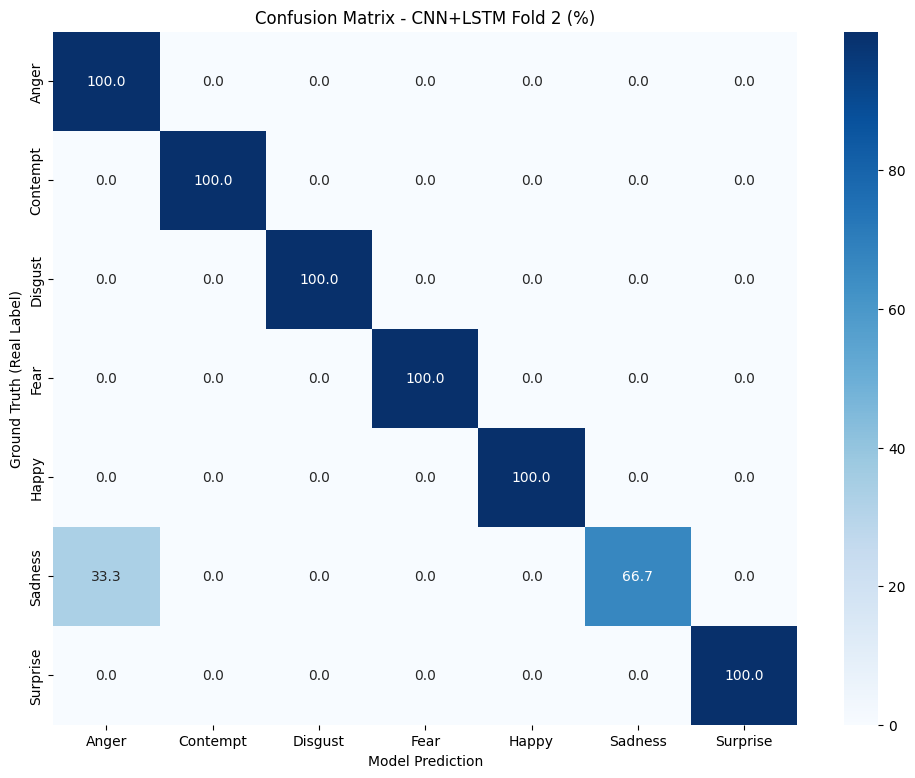


Detailed Classification Report:
              precision    recall  f1-score   support

       Anger       0.83      1.00      0.91         5
    Contempt       1.00      1.00      1.00         2
     Disgust       1.00      1.00      1.00         6
        Fear       1.00      1.00      1.00         3
       Happy       1.00      1.00      1.00         7
     Sadness       1.00      0.67      0.80         3
    Surprise       1.00      1.00      1.00         9

    accuracy                           0.97        35
   macro avg       0.98      0.95      0.96        35
weighted avg       0.98      0.97      0.97        35



In [57]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

class EmotionCNN_LSTM(nn.Module):
    def __init__(self, num_classes=7, hidden_dim=256, num_layers=1, dropout=0.5):
        super().__init__()
        
        # 1. Extractorul 2D (ResNet18)
        resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
        # Păstrăm totul în afară de layer-ul final (fc). 
        # AdaptiveAvgPool2d rămâne, deci output-ul este (B, 512, 1, 1)
        self.cnn = nn.Sequential(*list(resnet.children())[:-1]) 
        self.cnn_out_dim = 512
        
        # 2. Modulul Temporal (LSTM)
        self.lstm = nn.LSTM(
            input_size=self.cnn_out_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        # 3. Capul de Clasificare
        self.fc = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout * 0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # R3D se aștepta la (B, C, T, H, W). 
        # Ne asigurăm că formatul este (B, T, C, H, W) pentru LSTM.
        if x.dim() == 5 and x.shape[1] == 3:
            x = x.permute(0, 2, 1, 3, 4) 
            
        B, T, C, H, W = x.shape
        
        # Facem flatten la Batch și Time pentru a procesa toate imaginile simultan prin CNN
        c_in = x.contiguous().view(B * T, C, H, W)
        
        # Extragem trăsăturile
        cnn_out = self.cnn(c_in)          # Output: (B*T, 512, 1, 1)
        cnn_out = cnn_out.view(B, T, -1)  # Re-separăm cadrele: (B, T, 512)
        
        # Trecem prin LSTM
        lstm_out, (h_n, c_n) = self.lstm(cnn_out) 
        
        # Luăm starea ascunsă de la ultimul cadru (apex-ul expresiei)
        last_hidden_state = h_n[-1, :, :] # Output: (B, hidden_dim)
        
        logits = self.fc(last_hidden_state)
        return logits, None  # (logits, _) pentru a păstra compatibilitatea cu run_epoch

# 1. Configuration & Model Setup
MODEL_PATH = 'best_cnn_lstm_fold5v2.pth'
TARGET_FOLD = 2  # Matches your filename
emotion_labels = ['Anger', 'Contempt', 'Disgust', 'Fear', 'Happy', 'Sadness', 'Surprise']

# Initialize the architecture (must match exactly the one used during training)
eval_model = EmotionCNN_LSTM(num_classes=7, hidden_dim=256).to(DEVICE)

minimal_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),               # Required: Model expects this size
    transforms.Grayscale(num_output_channels=3), # Required: Model expects 3 channels
    transforms.ToTensor(),                       # Required: Converts 0-255 to 0.0-1.0
    transforms.Normalize(EFFICIENTNET_MEAN, EFFICIENTNET_STD), # Required: Centers the data
])

# Load the saved weights
try:
    eval_model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
    print(f"Successfully loaded: {MODEL_PATH}")
except Exception as e:
    print(f"Error loading model: {e}")

# 2. Re-create the Test Loader for Fold 2
# This ensures we are testing on the data the model didn't see during its specific training fold
eval_dataset = CKPlusDataset(
    csv_path=CSV_PATH, 
    images_dir=IMAGES_DIR,
    fold_to_use=TARGET_FOLD, 
    is_train=False, 
    random_seed=42,
    transform = minimal_test_transform
)
eval_loader = DataLoader(eval_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 3. Refined Confusion Matrix Function
def plot_final_evaluation(model, loader, device, classes):
    model.eval()
    all_preds = []
    all_labels = []
    
    print("Running evaluation...")
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            
            # The model's forward() already handles permutations, 
            # so we just pass the inputs directly.
            logits, _ = model(inputs)
            preds = torch.argmax(logits, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    # Calculate Matrix
    cm = confusion_matrix(all_labels, all_preds)
    # Avoid division by zero if a class has no samples in this fold
    cm_perc = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-9) * 100 
    
    # Visualization
    plt.figure(figsize=(12, 9))
    sns.heatmap(cm_perc, annot=True, fmt='.1f', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    
    plt.ylabel('Ground Truth (Real Label)')
    plt.xlabel('Model Prediction')
    plt.title(f'Confusion Matrix - CNN+LSTM Fold {TARGET_FOLD} (%)')
    plt.show()

    # Detailed Report
    print("\nDetailed Classification Report:")
    print(classification_report(all_labels, all_preds, target_names=classes, zero_division=0))

# 4. Run it
plot_final_evaluation(eval_model, eval_loader, DEVICE, emotion_labels)

In [39]:
import cv2
import numpy as np

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Hooks to capture gradients and activations
        self.target_layer.register_forward_hook(self.save_activations)
        self.target_layer.register_full_backward_hook(self.save_gradients)

    def save_activations(self, module, input, output):
        self.activations = output

    def save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, target_class=None):
        """
        input_tensor: (1, T, C, H, W)
        """
        # 1. Temporarily disable cuDNN to allow backward pass through LSTM in eval mode
        # This is the cleanest fix for the RuntimeError you encountered.
        torch.backends.cudnn.enabled = False
        
        self.model.eval()
        logits, _ = self.model(input_tensor)

        if target_class is None:
            target_class = torch.argmax(logits, dim=1).item()

        # 2. Backward pass
        self.model.zero_grad()
        loss = logits[0, target_class]
        loss.backward()
        
        # Re-enable cuDNN immediately after backward
        torch.backends.cudnn.enabled = True

        # 3. Process the last frame (Apex)
        # self.activations and self.gradients were captured during forward/backward
        T = input_tensor.shape[1]
        idx = T - 1 # Index for the last frame in the sequence
        
        # Get gradients and activations for that specific frame
        # Shape will be (Channels, H, W) -> e.g., (512, 7, 7)
        grads = self.gradients[idx].cpu().data.numpy()      
        target_activations = self.activations[idx].cpu().data.numpy() 

        # 4. Global Average Pooling of gradients
        weights = np.mean(grads, axis=(1, 2)) 

        # 5. Weighted combination of activation maps
        cam = np.zeros(target_activations.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            cam += w * target_activations[i, :, :]

        # 6. Post-processing: ReLU and Normalization
        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (224, 224))
        
        # Avoid division by zero
        heatmap_min, heatmap_max = np.min(cam), np.max(cam)
        cam = (cam - heatmap_min) / (heatmap_max - heatmap_min + 1e-9)
        
        return cam

def overlay_heatmap(img_pil, heatmap):
    img = np.array(img_pil.convert('RGB'))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    
    # Superimpose heatmap on image
    overlayed = cv2.addWeighted(img, 0.6, heatmap, 0.4, 0)
    return overlayed

In [ ]:
import torch

# 1. Definim Device-ul
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Instanțiem clasa modelului 
# ATENȚIE: Trebuie să folosești aceiași parametri (num_classes, hidden_dim etc.) 
# pe care i-ai folosit la antrenare.
model = EmotionCNN_LSTM(num_classes=7) 

# 3. Încărcăm "state_dict"-ul (greutățile)
checkpoint_path = "best_cnn_lstm_fold7v2.pth"

# Folosim map_location pentru a ne asigura că modelul se încarcă 
# chiar dacă a fost salvat pe GPU și acum îl rulăm pe CPU (sau invers)
state_dict = torch.load(checkpoint_path, map_location=device)

# 4. Încărcăm greutățile în model
model.load_state_dict(state_dict)

# 5. Mutăm modelul pe device-ul corect și îl trecem în modul de evaluare
model.to(device)
model.eval()

print(f"Modelul a fost încărcat cu succes din {checkpoint_path} pe {device}!")

In [56]:
import os
from tqdm import tqdm
import cv2

def export_dataset_gradcam(model, loader, cam_engine, output_dir, device, classes):
    model.eval()
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
        for cls in classes:
            os.makedirs(os.path.join(output_dir, cls), exist_ok=True)
            
    print(f"Procesăm {len(loader.dataset)} secvențe...")
    
    sample_idx = 0
    for inputs, labels in tqdm(loader):
        inputs = inputs.to(device)  # (Batch, Timp, Canale, H, W)
        labels = labels.to(device)
        batch_size = inputs.size(0)
        
        for i in range(batch_size):
            # 1. Izolăm secvența curentă -> Shape: (1, T, C, H, W)
            input_tensor = inputs[i:i+1] 
            target_label = labels[i].item()
            
            # 2. Obținem predicția modelului
            with torch.no_grad():
                logits, _ = model(input_tensor)
                pred_label = torch.argmax(logits, dim=1).item()
            
            # 3. Generăm Grad-CAM
            heatmap = cam_engine.generate_heatmap(input_tensor, target_class=pred_label)
            
            # 4. Găsim Apex Frame (ultimul cadru VALID care nu este padding cu 0)
            # Facem suma pe canale/H/W. Un cadru de padding va avea suma = 0.
            frame_sums = inputs[i].sum(dim=(1, 2, 3))
            valid_indices = (frame_sums > 0).nonzero(as_tuple=False)
            last_valid_idx = valid_indices[-1].item() if len(valid_indices) > 0 else inputs.size(1) - 1
            
            apex_tensor = inputs[i, last_valid_idx].cpu().clone()
            apex_img_pil = transforms.ToPILImage()(denormalize(apex_tensor))
            
            # 5. Overlay: Pregătim imaginile pentru OpenCV
            apex_img_cv = cv2.cvtColor(np.array(apex_img_pil), cv2.COLOR_RGB2BGR)
            
            # Ajustăm heatmap-ul la dimensiunea imaginii (224x224)
            if isinstance(heatmap, torch.Tensor):
                heatmap = heatmap.squeeze().cpu().numpy()
            if heatmap.shape != (224, 224):
                heatmap = cv2.resize(heatmap, (224, 224))
                
            heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
            
            # Combinăm imaginea cu harta de activare
            result_img = cv2.addWeighted(apex_img_cv, 0.6, heatmap_color, 0.4, 0)
            
            # 6. Salvare
            gt_name = classes[target_label]
            pred_name = classes[pred_label]
            status = "PASS" if target_label == pred_label else f"FAIL_as_{pred_name}"
            
            filename = f"sample_{sample_idx:03d}_{status}.jpg"
            save_path = os.path.join(output_dir, gt_name, filename)
            
            cv2.imwrite(save_path, result_img)
            sample_idx += 1

# --- RUNNING THE EXPORT ---

# Ensure denormalize matches your ResNet/EfficientNet training stats
def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return torch.clamp(tensor * std + mean, 0, 1)

import torch
from torchvision import transforms
import os

# (Asigură-te că ai importat clasa GradCAM pe care o folosești din biblioteca ta)
# from util import GradCAM # sau orice bibliotecă folosești

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
emotion_labels = ['Anger', 'Contempt', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise']

# 1. Instanțiem și încărcăm modelul
eval_model = EmotionCNN_LSTM(num_classes=7).to(DEVICE)
checkpoint_path = "best_cnn_lstm_fold5v2.pth"

# Folosim weights_only=True pentru siguranță la load
state_dict = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
eval_model.load_state_dict(state_dict)
eval_model.eval()

eval_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(EFFICIENTNET_MEAN, EFFICIENTNET_STD),
])

# 2. Pregătirea datelor
eval_dataset = CKPlusDataset(
    csv_path="bigdata/md5_s9055eb881c182cc82d1ab85ba6c/licenta/csnn_simulator/dataset/CK+/emotions_dataset.csv",
    images_dir="CK_Plus_Cropped",
    fold_to_use=7,
    is_train=False,
    transform=eval_test_transform # Asigură-te că test_transform e definit (Resize, Grayscale->3ch, ToTensor, Normalize)
)

# CRITIC: Am adăugat `collate_fn=pad_collate_fn` pentru a rezolva problema secvențelor inegale
eval_loader = DataLoader(eval_dataset, batch_size=8, shuffle=False)

# 3. Inițializare Grad-CAM
# Vizăm ultimul layer al extracției ResNet18 din clasa ta EmotionCNN_LSTM
cam_engine = GradCAM(eval_model, eval_model.cnn[7])

# 4. Rularea exportului către folderul ales (ex. folderul "X")
print("Începem generarea vizualizărilor Grad-CAM...")
export_dataset_gradcam(
    model=eval_model,
    loader=eval_loader,
    cam_engine=cam_engine,
    output_dir="GradCAM_Analysis_Fold5", # Folderul X în care vrei rezultatele
    device=DEVICE,
    classes=emotion_labels
)

print("Operațiune finalizată cu succes!")

Începem generarea vizualizărilor Grad-CAM...
Procesăm 32 secvențe...


100%|██████████| 4/4 [00:02<00:00,  1.84it/s]

Operațiune finalizată cu succes!


In [ ]:
# incerc cu poze 48x48

In [60]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader


train_transform = transforms.Compose([
    transforms.Resize((48, 48)),
    transforms.Grayscale(num_output_channels=3),  # CK+ is grayscale → repeat to 3ch
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(EFFICIENTNET_MEAN, EFFICIENTNET_STD),
])

test_transform = transforms.Compose([
    transforms.Resize((48, 48)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(EFFICIENTNET_MEAN, EFFICIENTNET_STD),
])

# ── 1. Arhitectura Modelului ──────────────────────────────────────────────────

class EmotionCNN_LSTM(nn.Module):
    def __init__(self, num_classes=7, hidden_dim=256, num_layers=1, dropout=0.5):
        super().__init__()
        
        # 1. Extractorul 2D (ResNet18)
        resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
        # Păstrăm totul în afară de layer-ul final (fc). 
        # AdaptiveAvgPool2d rămâne, deci output-ul este (B, 512, 1, 1)
        self.cnn = nn.Sequential(*list(resnet.children())[:-1]) 
        self.cnn_out_dim = 512
        
        # 2. Modulul Temporal (LSTM)
        self.lstm = nn.LSTM(
            input_size=self.cnn_out_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        # 3. Capul de Clasificare
        self.fc = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout * 0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # R3D se aștepta la (B, C, T, H, W). 
        # Ne asigurăm că formatul este (B, T, C, H, W) pentru LSTM.
        if x.dim() == 5 and x.shape[1] == 3:
            x = x.permute(0, 2, 1, 3, 4) 
            
        B, T, C, H, W = x.shape
        
        # Facem flatten la Batch și Time pentru a procesa toate imaginile simultan prin CNN
        c_in = x.contiguous().view(B * T, C, H, W)
        
        # Extragem trăsăturile
        cnn_out = self.cnn(c_in)          # Output: (B*T, 512, 1, 1)
        cnn_out = cnn_out.view(B, T, -1)  # Re-separăm cadrele: (B, T, 512)
        
        # Trecem prin LSTM
        lstm_out, (h_n, c_n) = self.lstm(cnn_out) 
        
        # Luăm starea ascunsă de la ultimul cadru (apex-ul expresiei)
        last_hidden_state = h_n[-1, :, :] # Output: (B, hidden_dim)
        
        logits = self.fc(last_hidden_state)
        return logits, None  # (logits, _) pentru a păstra compatibilitatea cu run_epoch


# ── 2. Funcția de control al greutăților ──────────────────────────────────────

def set_trainable_layers_lstm(model, phase):
    """
    Phase 1: Doar LSTM și FC (antrenăm capul temporal să înțeleagă trăsăturile ResNet)
    Phase 2: Layer4 (din CNN) + LSTM + FC (fine-tuning delicat)
    """
    # 1. Înghețăm absolut tot
    for param in model.parameters():
        param.requires_grad = False
        
    # 2. Dezghețăm selectiv
    if phase == 1:
        for param in model.lstm.parameters(): param.requires_grad = True
        for param in model.fc.parameters():   param.requires_grad = True
            
    elif phase == 2:
        # Layer 4 în ResNet18 standard este la indexul 7 în `children()`
        for param in model.cnn[7].parameters(): param.requires_grad = True
        for param in model.lstm.parameters():   param.requires_grad = True
        for param in model.fc.parameters():     param.requires_grad = True

    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  Trainable params (Phase {phase}): {n_trainable:,}")


# ── 3. Bucla de Antrenare ─────────────────────────────────────────────────────

PHASE1_EPOCHS = 10   # Lăsăm puțin mai mult timp LSTM-ului să se stabilizeze
PHASE2_EPOCHS = 30   # Epoci de fine-tuning
BATCH_SIZE    = 16   # Poți crește la 32 dacă îți permite memoria GPU-ului
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CSV_PATH = "bigdata/md5_s9055eb881c182cc82d1ab85ba6c/licenta/csnn_simulator/dataset/CK+/emotions_dataset.csv"
IMAGES_DIR = "CK_Plus_Cropped"

NUM_FOLDS = 10

all_fold_accuracies = []

for fold in range(1, NUM_FOLDS + 1):
    print(f"\n{'='*55}\nFOLD {fold}\n{'='*55}")

    train_dataset = CKPlusDataset(
        csv_path=CSV_PATH, images_dir=IMAGES_DIR,
        fold_to_use=fold, is_train=True, random_seed=42,
        transform=train_transform,
    )
    test_dataset = CKPlusDataset(
        csv_path=CSV_PATH, images_dir=IMAGES_DIR,
        fold_to_use=fold, is_train=False, random_seed=42,
        transform=test_transform,
    )

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

    # Inițializăm noul model
    model     = EmotionCNN_LSTM(num_classes=7).to(DEVICE)
    # Folosim un pic mai mult label smoothing pentru a combate overfitting-ul
    criterion = nn.CrossEntropyLoss(label_smoothing=0.15) 

    # ── Phase 1: LSTM + Head Only ─────────────────────────────────────────────
    print(f"\n[Phase 1] Warm-up LSTM & Head ({PHASE1_EPOCHS} epochs)")
    set_trainable_layers_lstm(model, phase=1)

    opt1 = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=1e-3, weight_decay=1e-4
    )

    for epoch in range(1, PHASE1_EPOCHS + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, opt1, DEVICE, train=True)
        te_loss, te_acc = run_epoch(model, test_loader,  criterion, None, DEVICE, train=False)
        print(f"  {epoch:2d}/{PHASE1_EPOCHS} | Train {tr_acc:.1f}% | Test {te_acc:.1f}%")

    # ── Phase 2: CNN(Layer4) + LSTM + Head ────────────────────────────────────
    print(f"\n[Phase 2] Fine-tune Layer4 + LSTM ({PHASE2_EPOCHS} epochs)")
    set_trainable_layers_lstm(model, phase=2)

    # LR mult mai mic (1e-4 în loc de 3e-4) pentru a nu distruge ponderile ResNet-ului
    opt2 = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=1e-4, weight_decay=1e-2  # weight_decay crescut pentru regularizare
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=PHASE2_EPOCHS, eta_min=1e-6)

    best_acc, patience_count = 0.0, 0
    PATIENCE = 10  # Oprim dacă nu avem îmbunătățiri timp de 10 epoci

    for epoch in range(1, PHASE2_EPOCHS + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, opt2, DEVICE, train=True)
        te_loss, te_acc = run_epoch(model, test_loader,  criterion, None, DEVICE, train=False)
        scheduler.step()

        gap  = tr_acc - te_acc
        flag = ""
        if te_acc > best_acc:
            best_acc = te_acc
            patience_count = 0
            # torch.save(model.state_dict(), f"best_cnn_lstm_fold{fold}v2.pth")
            flag = " ★"
        else:
            patience_count += 1

        print(f"  {epoch:2d}/{PHASE2_EPOCHS} | "
              f"Train {tr_acc:.1f}% | Test {te_acc:.1f}% | "
              f"Gap {gap:+.1f}%{flag}")

        if patience_count >= PATIENCE:
            print(f"  Early stop — no improvement for {PATIENCE} epochs.")
            break

    all_fold_accuracies.append(best_acc)

    print(f"\nFold {fold} best: {best_acc:.2f}%")

# DUPĂ ce se termină bucla de 10 fold-uri:
import numpy as np

mean_acc = np.mean(all_fold_accuracies)
std_acc = np.std(all_fold_accuracies)

print(f"\nFinal Cross-Validation Results:")
print(f"Mean Accuracy: {mean_acc:.2f}%")
print(f"Standard Deviation: {std_acc:.2f}%")


FOLD 1

[Phase 1] Warm-up LSTM & Head (10 epochs)
  Trainable params (Phase 1): 822,279
   1/10 | Train 27.5% | Test 27.3%
   2/10 | Train 27.9% | Test 39.4%
   3/10 | Train 37.7% | Test 39.4%
   4/10 | Train 36.2% | Test 42.4%
   5/10 | Train 39.9% | Test 39.4%
   6/10 | Train 43.8% | Test 42.4%
   7/10 | Train 47.1% | Test 42.4%
   8/10 | Train 44.6% | Test 39.4%
   9/10 | Train 48.2% | Test 39.4%
  10/10 | Train 48.2% | Test 48.5%

[Phase 2] Fine-tune Layer4 + LSTM (30 epochs)
  Trainable params (Phase 2): 9,216,007
   1/30 | Train 51.8% | Test 54.5% | Gap -2.7% ★
   2/30 | Train 58.3% | Test 51.5% | Gap +6.8%
   3/30 | Train 58.7% | Test 54.5% | Gap +4.2%
   4/30 | Train 62.7% | Test 51.5% | Gap +11.2%
   5/30 | Train 65.9% | Test 60.6% | Gap +5.3% ★
   6/30 | Train 67.8% | Test 51.5% | Gap +16.2%
   7/30 | Train 70.3% | Test 54.5% | Gap +15.7%
   8/30 | Train 73.9% | Test 57.6% | Gap +16.3%
   9/30 | Train 69.9% | Test 60.6% | Gap +9.3%
  10/30 | Train 71.7% | Test 57.6% | Gap +1

In [61]:
from collections import Counter

# Obținem toate etichetele din dataset (atenție: labels sunt indexate de la 0 la 6)
train_labels = [label.item() for _, label in train_dataset]
test_labels = [label.item() for _, label in test_dataset]

train_counts = Counter(train_labels)
test_counts = Counter(test_labels)

print("\nDistribuție clase în TEST:")
for i, label_name in enumerate(emotion_labels):
    print(f"  {label_name}: {test_counts[i]} samples")


Distribuție clase în TEST:
  Anger: 4 samples
  Contempt: 0 samples
  Disgust: 5 samples
  Fear: 2 samples
  Happy: 6 samples
  Sadness: 2 samples
  Surprise: 7 samples


In [62]:
from collections import Counter

all_labels = []
for _, labels in eval_loader:
    all_labels.extend(labels.tolist())

counts = Counter(all_labels)
print("Distribuția REALĂ în loader-ul de test:")
for i, name in enumerate(emotion_labels):
    print(f"  {name} (clasa {i}): {counts[i]} samples")

print(f"Total mostre în loader: {sum(counts.values())}")

Distribuția REALĂ în loader-ul de test:
  Anger (clasa 0): 5 samples
  Contempt (clasa 1): 2 samples
  Disgust (clasa 2): 6 samples
  Fear (clasa 3): 3 samples
  Happy (clasa 4): 7 samples
  Sadness (clasa 5): 3 samples
  Surprise (clasa 6): 9 samples
Total mostre în loader: 35


In [63]:
# Rulează asta după ce ai inițializat variabila dataset
print("--- ANALIZĂ SECVENȚE LIPSA ---")
missing_count = 0
for seq in all_sequences: # all_sequences e lista citită din CSV
    subject = seq['subject']
    ipostase_str = f"{seq['ipostase']:03d}"
    seq_dir = os.path.join(IMAGES_DIR, subject, ipostase_str)
    
    if not os.path.exists(seq_dir):
        if seq['emotion'] == 2: # 2 este Contempt în CSV-ul tău (indexat de la 1)
            print(f"LIPSEȘTE CONTEMPT: Folderul {seq_dir} nu există!")
        missing_count += 1

print(f"\nTotal secvențe din CSV care nu au folder pe disc: {missing_count}")

--- ANALIZĂ SECVENȚE LIPSA ---


NameError: name 'all_sequences' is not defined

In [64]:
from collections import Counter

def print_dataset_stats(dataset, name):
    print(f"--- Statistici pentru {name} ---")
    print(f"Total secvențe: {len(dataset)}")
    
    # Extragem toate label-urile (atenție: în .data ele sunt încă cele originale din CSV)
    labels = [seq['emotion'] for seq in dataset.data]
    counts = Counter(labels)
    
    # Mapare pentru CK+ (standard)
    # 1=Anger, 2=Contempt, 3=Disgust, 4=Fear, 5=Happy, 6=Sadness, 7=Surprise
    emotion_map = {
        1: "Anger", 2: "Contempt", 3: "Disgust", 4: "Fear", 
        5: "Happy", 6: "Sadness", 7: "Surprise"
    }
    
    for emotion_id in sorted(counts.keys()):
        name = emotion_map.get(emotion_id, f"Unknown({emotion_id})")
        count = counts[emotion_id]
        percentage = (count / len(dataset)) * 100
        print(f"  Label {emotion_id} ({name}): {count} secvențe ({percentage:.2f}%)")
    print("\n")

# Folosire:
print_dataset_stats(train_dataset, "Setul de Antrenare")
print_dataset_stats(test_dataset, "Setul de Test")

--- Statistici pentru Setul de Antrenare ---
Total secvențe: 283
  Label 1 (Anger): 41 secvențe (14.49%)
  Label 2 (Contempt): 12 secvențe (4.24%)
  Label 3 (Disgust): 49 secvențe (17.31%)
  Label 4 (Fear): 22 secvențe (7.77%)
  Label 5 (Happy): 63 secvențe (22.26%)
  Label 6 (Sadness): 26 secvențe (9.19%)
  Label 7 (Surprise): 70 secvențe (24.73%)


--- Statistici pentru Setul de Test ---
Total secvențe: 26
  Label 1 (Anger): 4 secvențe (15.38%)
  Label 3 (Disgust): 5 secvențe (19.23%)
  Label 4 (Fear): 2 secvențe (7.69%)
  Label 5 (Happy): 6 secvențe (23.08%)
  Label 6 (Sadness): 2 secvențe (7.69%)
  Label 7 (Surprise): 7 secvențe (26.92%)




In [66]:
from collections import Counter
all_labels_in_test = [seq['emotion'] for seq in eval_dataset.data]
print(f"Distribuția REALĂ în setul de test (Fold {TARGET_FOLD}):", Counter(all_labels_in_test))

Distribuția REALĂ în setul de test (Fold 2): Counter({7: 9, 5: 7, 3: 6, 1: 5, 6: 3, 4: 3, 2: 2})
